In [1]:
from langgraph.graph import StateGraph, START, MessagesState
from langgraph.checkpoint.memory import InMemorySaver
from langchain_core.messages.utils import trim_messages,count_tokens_approximately

from langchain_google_genai import ChatGoogleGenerativeAI
from dotenv import load_dotenv

load_dotenv()

model = ChatGoogleGenerativeAI(
    model="gemini-2.5-flash",
    temperature=0
)

In [2]:
MAX_TOKENS = 150

In [3]:
def call_model(state: MessagesState):
    
    # Trim conversation history -> last N messages that fit within the token budget
    messages = trim_messages(
        state["messages"],
        strategy="last",                      
        token_counter=count_tokens_approximately,
        max_tokens=MAX_TOKENS
    )

    print('Current Token Count ->', count_tokens_approximately(messages=messages))

    for message in messages:
        print(message.content)

    response = model.invoke(messages)

    return {"messages": [response]}

In [4]:
builder = StateGraph(MessagesState)
builder.add_node("call_model", call_model)
builder.add_edge(START, "call_model")

In [5]:
checkpointer = InMemorySaver()
graph = builder.compile(checkpointer=checkpointer)

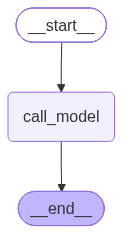

In [6]:
graph

In [7]:
config = {"configurable": {"thread_id": "chat-1"}}

result = graph.invoke(
    {"messages": [{"role": "user", "content": "Hi, my name is Nitish."}]},
    config,
)

result["messages"][-1].content

Current Token Count -> 10
Hi, my name is Nitish.


Direct use of automatic function calling (AFC) in Models.generate_content is not recommended. Instead, we recommend to use AFC in Chat.send_message. Similarly, direct use of AFC in Models.generate_content_stream is not recommended. Instead, we recommend to use AFC in Chat.send_message_stream.


"Hi Nitish! Nice to meet you.\n\nI'm an AI assistant, and I don't have a personal name like you do.\n\nHow can I help you today?"

In [11]:
result = graph.invoke(
    {"messages": [{"role": "user", "content": "I am learning LangGraph."}]},
    config,
)

result["messages"][-1].content

Current Token Count -> 89
What is my name?
As an AI, I don't have access to personal information about you, including your name. I don't retain details from our conversations or know who you are personally.

If you'd like me to refer to you by a specific name during this chat, please feel free to tell me!
I am learning LangGraph.


"That's fantastic! LangGraph is a really powerful and exciting library for building robust, stateful, and agentic LLM applications. It's a great step beyond simple chains and allows for much more complex, dynamic workflows with loops and conditional logic.\n\nWhat aspects are you currently exploring or finding most interesting? Are you working on a specific project, or just diving into the core concepts like nodes, edges, state, and graph types (like `StateGraph` or `MessageGraph`)?\n\nI can help with:\n*   Explaining concepts\n*   Providing examples\n*   Discussing best practices\n*   Troubleshooting issues you might encounter\n\nFeel free to ask me anything about it!"

In [12]:
result = graph.invoke(
    {"messages": [{"role": "user", "content": "Can you explain short term memory?"}]},
    config,
)

result["messages"][-1].content

Current Token Count -> 13
Can you explain short term memory?


'Short-term memory (STM) is a memory system that holds a limited amount of information for a brief period of time, typically a few seconds, while it\'s being actively used or processed. It\'s like your brain\'s temporary "scratchpad" or "mental workspace."\n\nHere\'s a breakdown of its key characteristics:\n\n1.  **Limited Capacity:** STM can only hold a small amount of information at any given time. The classic estimate, proposed by George A. Miller, is "7 plus or minus 2" items (or "chunks" of information). A "chunk" can be a single digit, a letter, or even a meaningful word or phrase. For example, it\'s easier to remember "FBI-CIA-IRS" (3 chunks) than "F-B-I-C-I-A-I-R-S" (9 chunks).\n\n2.  **Short Duration:** Information in STM is very fragile and decays quickly if not actively rehearsed or transferred to long-term memory. Without rehearsal, information typically lasts only about 15-30 seconds.\n\n3.  **Active and Conscious:** The information in your short-term memory is what you ar

In [13]:
result = graph.invoke(
    {"messages": [{"role": "user", "content": "What is my name?"}]},
    config,
)

result["messages"][-1].content

Current Token Count -> 8
What is my name?


"As an AI, I don't know your name. I don't have access to personal information about you.\n\nIf you'd like me to know your name for our conversation, feel free to tell me!"

In [14]:
for item in graph.get_state({"configurable": {"thread_id": "chat-1"}}).values['messages']:
    print(item.content)
    print('-'*120)

Hi, my name is Nitish.
------------------------------------------------------------------------------------------------------------------------
Hi Nitish! Nice to meet you.

I'm an AI assistant, and I don't have a personal name like you do.

How can I help you today?
------------------------------------------------------------------------------------------------------------------------
I am learning LangGraph.
------------------------------------------------------------------------------------------------------------------------
That's excellent! LangGraph is a fantastic framework for building robust, stateful, and multi-step LLM applications. It really shines when you need to:

*   **Orchestrate complex sequences** of LLM calls, tool usage, and human interactions.
*   **Manage state** across multiple steps.
*   **Implement conditional logic** and loops (like self-correction or multi-agent dialogues).
*   **Build agents** that can reason and act over time.

It's essentially a way to de